## Figure 2

Representative XAS and XMCD spectra

Repository root: <repository>

Spectrum definitions:
  XAS  = (I_r + I_l) / 2
  XMCD = I_r - I_l

Fixed parameter selection:
  Sl     = 0.7
  SOC2p  = 0.9
  SOC3d  = 1.06

Spectrum-selection summary

Fe
  Directory                   : quanty/runs/Fe_d6/spec
  all_spec_files              : 15120
  all_right_xas_files         : 3780
  all_xmcd_files              : 3780
  selected_xas_pairs          : 70
  selected_xmcd               : 70
  skipped_wrong_prefix        : 0
  skipped_fixed_parameters    : 7420
  skipped_missing_parameters  : 0
  skipped_missing_left_file   : 0

Co
  Directory                   : quanty/runs/Co_d7/spec
  all_spec_files              : 15120
  all_right_xas_files         : 3780
  all_xmcd_files              : 3780
  selected_xas_pairs          : 70
  selected_xmcd               : 70
  skipped_wrong_prefix        : 0
  skipped_fixed_parameters    : 7420
  skipped_missing_parameters  : 0
  skipped_missing_left_file   : 0

Ni
  Directory                   : quant

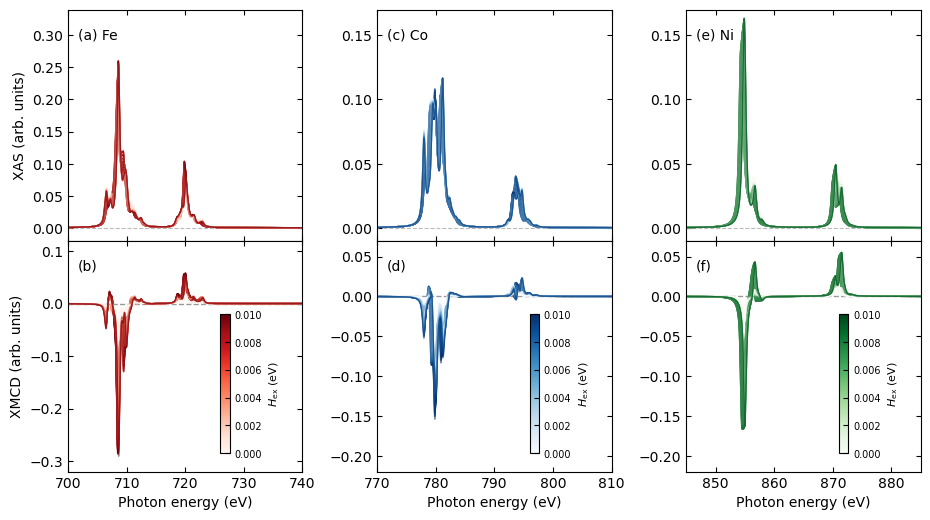


Selected 10Dq values
0.800000
0.888900
0.977800
1.066700
1.155600
1.244400
1.333300
1.422200
1.511100
1.600000

Selected Hex values
0.000000
0.001667
0.003333
0.005000
0.006667
0.008333
0.010000

Number of 10Dq values : 10
Number of Hex values  : 7
Total combinations    : 70

Plotted spectrum counts
Fe: XAS=70, XMCD=70
Co: XAS=70, XMCD=70
Ni: XAS=70, XMCD=70

PNG saved: figures/Figure2_XAS_XMCD_multi_element.png
PDF saved: figures/Figure2_XAS_XMCD_multi_element.pdf


In [1]:
#!/usr/bin/env python3

"""Generate Figure 2 from calculated XAS and XMCD spectra.

The XAS spectrum is defined as:

    XAS = (I_r + I_l) / 2

where I_r and I_l are loaded from *_r.spec and *_l.spec,
respectively.

The XMCD spectrum is loaded from:

    *_cd.spec

and is assumed to represent:

    XMCD = I_r - I_l

The script selects spectra corresponding to fixed Sl, SOC2p,
and SOC3d values while varying 10Dq and Hex.

Absolute paths are used internally. Paths shown in normal
console output are converted to repository-relative paths.
"""

from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import (
    FormatStrFormatter,
    MultipleLocator,
)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ============================================================
# Settings
# ============================================================

figure_name = "Figure2"

elements = [
    "Fe",
    "Co",
    "Ni",
]

# Fixed calculation parameters used to select spectra.
fixed_parameters = {
    "Sl": 0.70,
    "SOC2p": 0.90,
    "SOC3d": 1.06,
}

parameter_tolerance = 1.0e-10

spectrum_skip_header = 4
spectrum_energy_column = 0
spectrum_intensity_column = 2

energy_rtol = 1.0e-10
energy_atol = 1.0e-12

output_dpi = 300


# ============================================================
# Spectrum suffixes and definitions
# ============================================================

xas_right_suffix = "_r.spec"
xas_left_suffix = "_l.spec"
xmcd_suffix = "_cd.spec"

xas_definition = "(I_r + I_l) / 2"
xmcd_definition = "I_r - I_l"


# ============================================================
# Repository-root detection
# ============================================================

def find_repository_root(
    start_directory=None,
):
    """
    Find the repository root by searching upward.

    The repository root is identified by the presence of both:

        src/
        configs/

    Parameters
    ----------
    start_directory : str, pathlib.Path, or None
        Starting directory. If None, the current working
        directory is used.

    Returns
    -------
    pathlib.Path
        Absolute repository-root path.
    """

    if start_directory is None:
        current_directory = (
            Path.cwd()
            .resolve()
        )

    else:
        current_directory = (
            Path(
                start_directory
            )
            .expanduser()
            .resolve()
        )

    candidates = [
        current_directory,
        *current_directory.parents,
    ]

    for candidate in candidates:
        if (
            (
                candidate
                / "src"
            ).is_dir()
            and (
                candidate
                / "configs"
            ).is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Expected parent directories containing "
        "both 'src' and 'configs'."
    )


repository_root = find_repository_root()

quanty_root = (
    repository_root
    / "quanty"
    / "runs"
)

output_directory = (
    repository_root
    / "figures"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Public path utility
# ============================================================

def repository_relative_path(
    path,
):
    """
    Convert a repository path to a relative POSIX path.

    Absolute paths are never returned.

    Parameters
    ----------
    path : str or pathlib.Path
        Path expected to be inside the repository.

    Returns
    -------
    str
        Repository-relative POSIX path.
    """

    path = (
        Path(
            path
        )
        .expanduser()
        .resolve(
            strict=False
        )
    )

    try:
        relative_path = path.relative_to(
            repository_root
        )

    except ValueError as exception:
        raise ValueError(
            "Path is outside the repository root"
        ) from exception

    return relative_path.as_posix()


# ============================================================
# Spectrum directories
# ============================================================

directories = {
    "Fe": (
        quanty_root
        / "Fe_d6"
        / "spec"
    ),

    "Co": (
        quanty_root
        / "Co_d7"
        / "spec"
    ),

    "Ni": (
        quanty_root
        / "Ni_d8"
        / "spec"
    ),
}

system_prefixes = {
    "Fe": "Fe_L23_d6__",
    "Co": "Co_L23_d7__",
    "Ni": "Ni_L23_d8__",
}


# ============================================================
# Plot settings
# ============================================================

x_ranges = {
    "Fe": (
        700,
        740,
    ),

    "Co": (
        770,
        810,
    ),

    "Ni": (
        845,
        885,
    ),
}

xas_ylim = {
    "Fe": (
        -0.02,
        0.34,
    ),

    "Co": (
        -0.01,
        0.17,
    ),

    "Ni": (
        -0.01,
        0.17,
    ),
}

xmcd_ylim = {
    "Fe": (
        -0.32,
        0.12,
    ),

    "Co": (
        -0.22,
        0.07,
    ),

    "Ni": (
        -0.22,
        0.07,
    ),
}

panel_upper = {
    "Fe": "(a) Fe",
    "Co": "(c) Co",
    "Ni": "(e) Ni",
}

panel_lower = {
    "Fe": "(b)",
    "Co": "(d)",
    "Ni": "(f)",
}

cmap_dict = {
    "Fe": plt.cm.Reds,
    "Co": plt.cm.Blues,
    "Ni": plt.cm.Greens,
}


# ============================================================
# Co and Ni XAS tick settings
# ============================================================

xas_fixed_tick_elements = (
    "Co",
    "Ni",
)

xas_major_tick_interval = 0.05

xas_tick_format = "%.2f"


# ============================================================
# Spectrum loader
# ============================================================

def load_quanty_spec(
    filename,
):
    """
    Load energy and intensity columns from a Quanty spectrum.

    Parameters
    ----------
    filename : str or pathlib.Path
        Quanty spectrum file.

    Returns
    -------
    tuple of numpy.ndarray
        Energy and intensity arrays.
    """

    filename = Path(
        filename
    )

    if not filename.is_file():
        raise FileNotFoundError(
            "Spectrum file was not found: "
            f"{filename.name}"
        )

    data = np.genfromtxt(
        filename,
        comments="#",
        skip_header=spectrum_skip_header,
        dtype=np.float64,
    )

    if data.size == 0:
        raise ValueError(
            f"Empty spectrum: {filename.name}"
        )

    if data.ndim == 1:
        data = data.reshape(
            1,
            -1,
        )

    if data.ndim != 2:
        raise ValueError(
            "Spectrum data must be two-dimensional: "
            f"{filename.name}"
        )

    required_column = max(
        spectrum_energy_column,
        spectrum_intensity_column,
    )

    if data.shape[
        1
    ] <= required_column:
        raise ValueError(
            f"Spectrum {filename.name} contains "
            f"{data.shape[1]} columns, but column "
            f"{required_column} was requested."
        )

    energy = np.asarray(
        data[
            :,
            spectrum_energy_column,
        ],
        dtype=np.float64,
    )

    intensity = np.asarray(
        data[
            :,
            spectrum_intensity_column,
        ],
        dtype=np.float64,
    )

    finite_mask = (
        np.isfinite(
            energy
        )
        & np.isfinite(
            intensity
        )
    )

    energy = energy[
        finite_mask
    ]

    intensity = intensity[
        finite_mask
    ]

    if energy.size == 0:
        raise ValueError(
            "Spectrum contains no finite data points: "
            f"{filename.name}"
        )

    if np.any(
        np.diff(
            energy
        )
        <= 0.0
    ):
        raise ValueError(
            "Energy grid is not strictly increasing: "
            f"{filename.name}"
        )

    return (
        energy,
        intensity,
    )


# ============================================================
# Spectrum-pair validation
# ============================================================

def validate_same_energy_grid(
    reference_name,
    reference_energy,
    comparison_name,
    comparison_energy,
):
    """
    Validate that two spectra use the same energy grid.
    """

    reference_energy = np.asarray(
        reference_energy,
        dtype=np.float64,
    )

    comparison_energy = np.asarray(
        comparison_energy,
        dtype=np.float64,
    )

    if (
        reference_energy.shape
        != comparison_energy.shape
    ):
        raise ValueError(
            "Energy-grid length differs between "
            f"{reference_name} and {comparison_name}: "
            f"{reference_energy.shape} != "
            f"{comparison_energy.shape}"
        )

    if not np.allclose(
        reference_energy,
        comparison_energy,
        rtol=energy_rtol,
        atol=energy_atol,
        equal_nan=False,
    ):
        maximum_difference = float(
            np.max(
                np.abs(
                    reference_energy
                    - comparison_energy
                )
            )
        )

        raise ValueError(
            "Energy grids differ between "
            f"{reference_name} and {comparison_name}. "
            "Maximum absolute difference: "
            f"{maximum_difference:.8e} eV"
        )


def construct_circular_average(
    right_file,
    left_file,
):
    """
    Construct XAS as the average of right- and left-circular
    absorption spectra.

    Parameters
    ----------
    right_file : str or pathlib.Path
        Right-circular spectrum.

    left_file : str or pathlib.Path
        Left-circular spectrum.

    Returns
    -------
    tuple of numpy.ndarray
        Energy and averaged intensity arrays.
    """

    energy_right, intensity_right = load_quanty_spec(
        right_file
    )

    energy_left, intensity_left = load_quanty_spec(
        left_file
    )

    validate_same_energy_grid(
        Path(
            right_file
        ).name,
        energy_right,
        Path(
            left_file
        ).name,
        energy_left,
    )

    xas_intensity = (
        intensity_right
        + intensity_left
    ) / 2.0

    if not np.isfinite(
        xas_intensity
    ).all():
        raise ValueError(
            "Constructed XAS contains non-finite values"
        )

    return (
        energy_right,
        xas_intensity,
    )


# ============================================================
# File-name utilities
# ============================================================

def extract_parameter(
    filename,
    parameter_name,
):
    """
    Extract a floating-point parameter from a file name.

    Supported examples include:

        Sl0.7000
        SOC3d1.0600
        Hex0.100000
        Hex-0.100000
        10Dq1.2000
    """

    filename = Path(
        filename
    ).name

    number_pattern = (
        r"([-+]?"
        r"(?:\d+(?:\.\d*)?|\.\d+)"
        r"(?:[eE][-+]?\d+)?)"
    )

    pattern = (
        re.escape(
            parameter_name
        )
        + number_pattern
    )

    match = re.search(
        pattern,
        filename,
    )

    if match is None:
        return None

    try:
        value = float(
            match.group(
                1
            )
        )

    except ValueError:
        return None

    if not np.isfinite(
        value
    ):
        return None

    return value


def matches_fixed_parameters(
    filename,
):
    """
    Check whether a spectrum matches the fixed parameter values.
    """

    for parameter_name, expected_value in (
        fixed_parameters.items()
    ):
        observed_value = extract_parameter(
            filename,
            parameter_name,
        )

        if observed_value is None:
            return False

        if not np.isclose(
            observed_value,
            expected_value,
            rtol=0.0,
            atol=parameter_tolerance,
        ):
            return False

    return True


def remove_exact_suffix(
    filename,
    suffix,
):
    """
    Remove an exact suffix from a file name.
    """

    filename = Path(
        filename
    ).name

    if not filename.endswith(
        suffix
    ):
        raise ValueError(
            f"{filename} does not end with {suffix}"
        )

    return filename[
        :-len(
            suffix
        )
    ]


# ============================================================
# Collect selected spectra
# ============================================================

records = {}

selection_summary = {}

all_hex_values = []

for element in elements:
    directory = directories[
        element
    ]

    if not directory.is_dir():
        raise NotADirectoryError(
            "Spectrum directory was not found: "
            f"{repository_relative_path(directory)}"
        )

    expected_prefix = system_prefixes[
        element
    ]

    all_spec_files = sorted(
        directory.glob(
            "*.spec"
        )
    )

    right_files = sorted(
        directory.glob(
            f"*{xas_right_suffix}"
        )
    )

    xmcd_files = sorted(
        directory.glob(
            f"*{xmcd_suffix}"
        )
    )

    selected_xas = []
    selected_xmcd = []

    skipped_wrong_prefix = 0
    skipped_fixed_parameters = 0
    skipped_missing_parameters = 0
    skipped_missing_left_file = 0

    # --------------------------------------------------------
    # XAS = (I_r + I_l) / 2
    # --------------------------------------------------------

    for right_file in right_files:
        if not right_file.name.startswith(
            expected_prefix
        ):
            skipped_wrong_prefix += 1
            continue

        if not matches_fixed_parameters(
            right_file.name
        ):
            skipped_fixed_parameters += 1
            continue

        dq_value = extract_parameter(
            right_file.name,
            "10Dq",
        )

        hex_value = extract_parameter(
            right_file.name,
            "Hex",
        )

        if (
            dq_value is None
            or hex_value is None
        ):
            skipped_missing_parameters += 1
            continue

        base_name = remove_exact_suffix(
            right_file.name,
            xas_right_suffix,
        )

        left_file = (
            directory
            / f"{base_name}{xas_left_suffix}"
        )

        if not left_file.is_file():
            skipped_missing_left_file += 1
            continue

        selected_xas.append(
            (
                right_file,
                left_file,
                dq_value,
                hex_value,
            )
        )

        all_hex_values.append(
            hex_value
        )

    # --------------------------------------------------------
    # XMCD
    # --------------------------------------------------------

    for xmcd_file in xmcd_files:
        if not xmcd_file.name.startswith(
            expected_prefix
        ):
            skipped_wrong_prefix += 1
            continue

        if not matches_fixed_parameters(
            xmcd_file.name
        ):
            skipped_fixed_parameters += 1
            continue

        dq_value = extract_parameter(
            xmcd_file.name,
            "10Dq",
        )

        hex_value = extract_parameter(
            xmcd_file.name,
            "Hex",
        )

        if (
            dq_value is None
            or hex_value is None
        ):
            skipped_missing_parameters += 1
            continue

        selected_xmcd.append(
            (
                xmcd_file,
                dq_value,
                hex_value,
            )
        )

        all_hex_values.append(
            hex_value
        )

    selected_xas = sorted(
        selected_xas,
        key=lambda record: (
            record[
                2
            ],
            record[
                3
            ],
            record[
                0
            ].name,
        ),
    )

    selected_xmcd = sorted(
        selected_xmcd,
        key=lambda record: (
            record[
                1
            ],
            record[
                2
            ],
            record[
                0
            ].name,
        ),
    )

    records[
        (
            element,
            "XAS",
        )
    ] = selected_xas

    records[
        (
            element,
            "XMCD",
        )
    ] = selected_xmcd

    selection_summary[
        element
    ] = {
        "all_spec_files": int(
            len(
                all_spec_files
            )
        ),

        "all_right_xas_files": int(
            len(
                right_files
            )
        ),

        "all_xmcd_files": int(
            len(
                xmcd_files
            )
        ),

        "selected_xas_pairs": int(
            len(
                selected_xas
            )
        ),

        "selected_xmcd": int(
            len(
                selected_xmcd
            )
        ),

        "skipped_wrong_prefix": int(
            skipped_wrong_prefix
        ),

        "skipped_fixed_parameters": int(
            skipped_fixed_parameters
        ),

        "skipped_missing_parameters": int(
            skipped_missing_parameters
        ),

        "skipped_missing_left_file": int(
            skipped_missing_left_file
        ),
    }


# ============================================================
# Selection report
# ============================================================

print(
    "Repository root: <repository>"
)

print()

print(
    "Spectrum definitions:"
)

print(
    f"  XAS  = {xas_definition}"
)

print(
    f"  XMCD = {xmcd_definition}"
)

print()

print(
    "Fixed parameter selection:"
)

for parameter_name, parameter_value in (
    fixed_parameters.items()
):
    print(
        f"  {parameter_name:6s} = "
        f"{parameter_value:.6g}"
    )

print()

print(
    "Spectrum-selection summary"
)

print(
    "=" * 70
)

for element in elements:
    summary = selection_summary[
        element
    ]

    print()

    print(
        element
    )

    print(
        "  Directory                   :",
        repository_relative_path(
            directories[
                element
            ]
        ),
    )

    for key, value in summary.items():
        print(
            f"  {key:28s}: {value}"
        )


# ============================================================
# Validate selected records
# ============================================================

missing_groups = []

for element in elements:
    if not records[
        (
            element,
            "XAS",
        )
    ]:
        missing_groups.append(
            f"{element} XAS"
        )

    if not records[
        (
            element,
            "XMCD",
        )
    ]:
        missing_groups.append(
            f"{element} XMCD"
        )

if missing_groups:
    raise RuntimeError(
        "No spectra matched the requested fixed parameters for: "
        + ", ".join(
            missing_groups
        )
        + ". Check the available file names and parameters."
    )

all_hex_values = np.asarray(
    all_hex_values,
    dtype=np.float64,
)

all_hex_values = all_hex_values[
    np.isfinite(
        all_hex_values
    )
]

if all_hex_values.size == 0:
    raise RuntimeError(
        "No finite Hex values were extracted "
        "from the selected files"
    )

hex_min = float(
    np.min(
        all_hex_values
    )
)

hex_max = float(
    np.max(
        all_hex_values
    )
)

if np.isclose(
    hex_min,
    hex_max,
    rtol=0.0,
    atol=0.0,
):
    margin = max(
        1.0e-12,
        abs(
            hex_min
        )
        * 1.0e-6,
    )

    hex_min -= margin
    hex_max += margin

norm = Normalize(
    vmin=hex_min,
    vmax=hex_max,
)

print()

print(
    f"Selected Hex range: "
    f"{hex_min:.8g} to {hex_max:.8g}"
)


# ============================================================
# Create figure
# ============================================================

figure = plt.figure(
    figsize=(
        11.0,
        6.0,
    )
)

grid = GridSpec(
    2,
    3,
    figure=figure,
    hspace=0.00,
    wspace=0.32,
)

axes = np.empty(
    (
        2,
        3,
    ),
    dtype=object,
)

for row in range(
    2
):
    for column in range(
        3
    ):
        if row == 0:
            axes[
                row,
                column,
            ] = figure.add_subplot(
                grid[
                    row,
                    column,
                ]
            )

        else:
            axes[
                row,
                column,
            ] = figure.add_subplot(
                grid[
                    row,
                    column,
                ],
                sharex=axes[
                    0,
                    column,
                ],
            )


# ============================================================
# Plot XAS and XMCD
# ============================================================

loaded_spectrum_counts = {}

for column, element in enumerate(
    elements
):
    cmap = cmap_dict[
        element
    ]

    xmin, xmax = x_ranges[
        element
    ]

    loaded_xas = 0
    loaded_xmcd = 0

    # --------------------------------------------------------
    # XAS = (I_r + I_l) / 2
    # --------------------------------------------------------

    axis = axes[
        0,
        column,
    ]

    for (
        right_file,
        left_file,
        dq_value,
        hex_value,
    ) in records[
        (
            element,
            "XAS",
        )
    ]:
        try:
            energy, intensity = construct_circular_average(
                right_file,
                left_file,
            )

        except (
            OSError,
            ValueError,
        ) as exception:
            print(
                "Warning: skipped XAS pair "
                f"{right_file.name} / "
                f"{left_file.name}: "
                f"{exception}"
            )
            continue

        axis.plot(
            energy,
            intensity,
            color=cmap(
                norm(
                    hex_value
                )
            ),
            linewidth=1.0,
            alpha=0.5,
        )

        loaded_xas += 1

    axis.set_xlim(
        xmin,
        xmax,
    )

    axis.set_ylim(
        xas_ylim[
            element
        ]
    )

    # Co and Ni XAS:
    # 0.05 major-tick spacing and two decimal places.
    if element in xas_fixed_tick_elements:
        axis.yaxis.set_major_locator(
            MultipleLocator(
                xas_major_tick_interval
            )
        )

        axis.yaxis.set_major_formatter(
            FormatStrFormatter(
                xas_tick_format
            )
        )

    axis.tick_params(
        labelbottom=False
    )

    axis.text(
        0.04,
        0.92,
        panel_upper[
            element
        ],
        transform=axis.transAxes,
        verticalalignment="top",
    )

    # --------------------------------------------------------
    # XMCD
    # --------------------------------------------------------

    axis = axes[
        1,
        column,
    ]

    for (
        xmcd_file,
        dq_value,
        hex_value,
    ) in records[
        (
            element,
            "XMCD",
        )
    ]:
        try:
            energy, intensity = load_quanty_spec(
                xmcd_file
            )

        except (
            OSError,
            ValueError,
        ) as exception:
            print(
                "Warning: skipped XMCD file "
                f"{xmcd_file.name}: "
                f"{exception}"
            )
            continue

        axis.plot(
            energy,
            intensity,
            color=cmap(
                norm(
                    hex_value
                )
            ),
            linewidth=1.0,
            alpha=0.5,
        )

        loaded_xmcd += 1

    axis.set_xlim(
        xmin,
        xmax,
    )

    axis.set_ylim(
        xmcd_ylim[
            element
        ]
    )

    axis.text(
        0.04,
        0.92,
        panel_lower[
            element
        ],
        transform=axis.transAxes,
        verticalalignment="top",
    )

    loaded_spectrum_counts[
        element
    ] = {
        "XAS": loaded_xas,
        "XMCD": loaded_xmcd,
    }


# ============================================================
# Axis labels
# ============================================================

axes[
    0,
    0,
].set_ylabel(
    "XAS (arb. units)"
)

axes[
    1,
    0,
].set_ylabel(
    "XMCD (arb. units)"
)

for column in range(
    3
):
    axes[
        1,
        column,
    ].set_xlabel(
        "Photon energy (eV)"
    )


# ============================================================
# Axis style
# ============================================================

for row in range(
    2
):
    for column in range(
        3
    ):
        axis = axes[
            row,
            column,
        ]

        if row == 0:
            zero_line_color = "#BBBBBB"
            zero_line_width = 0.8

        else:
            zero_line_color = "#999999"
            zero_line_width = 1.0

        axis.axhline(
            0.0,
            color=zero_line_color,
            linewidth=zero_line_width,
            linestyle="--",
            zorder=0,
        )

        axis.tick_params(
            direction="in",
            which="both",
            top=True,
            right=True,
        )


# ============================================================
# Color bars
# ============================================================

for column, element in enumerate(
    elements
):
    color_axis = axes[
        1,
        column,
    ]

    scalar_mappable = ScalarMappable(
        norm=norm,
        cmap=cmap_dict[
            element
        ],
    )

    scalar_mappable.set_array(
        []
    )

    colorbar_axis = inset_axes(
        color_axis,
        width="4%",
        height="60%",
        loc="lower right",
        bbox_to_anchor=(
            -0.28,
            0.05,
            1.0,
            1.0,
        ),
        bbox_transform=color_axis.transAxes,
        borderpad=0.5,
    )

    colorbar = figure.colorbar(
        scalar_mappable,
        cax=colorbar_axis,
    )

    colorbar.set_label(
        r"$H_{\mathrm{ex}}$ (eV)",
        fontsize=8,
    )

    colorbar.ax.tick_params(
        direction="in",
        labelsize=7,
    )


# ============================================================
# Validate plotted spectra
# ============================================================

for element in elements:
    counts = loaded_spectrum_counts[
        element
    ]

    if counts[
        "XAS"
    ] == 0:
        raise RuntimeError(
            f"No valid {element} XAS spectra were plotted"
        )

    if counts[
        "XMCD"
    ] == 0:
        raise RuntimeError(
            f"No valid {element} XMCD spectra were plotted"
        )


# ============================================================
# Save
# ============================================================

png_file = (
    output_directory
    / (
        f"{figure_name}_"
        "XAS_XMCD_multi_element.png"
    )
).resolve()

pdf_file = (
    output_directory
    / (
        f"{figure_name}_"
        "XAS_XMCD_multi_element.pdf"
    )
).resolve()

figure.canvas.draw()

png_metadata = {
    "Title": (
        "Calculated XAS and XMCD spectra"
    ),

    "Author": "",

    "Description": (
        "XAS is defined as the average of the "
        "right- and left-circular absorption spectra."
    ),

    "Software": "",
}

pdf_metadata = {
    "Title": (
        "Calculated XAS and XMCD spectra"
    ),

    "Author": "",

    "Subject": (
        "Calculated Fe, Co, and Ni XAS and XMCD spectra"
    ),

    "Keywords": (
        "XAS, XMCD, Quanty, Fe, Co, Ni"
    ),

    "Creator": "",

    "Producer": "",
}

figure.savefig(
    png_file,
    dpi=output_dpi,
    format="png",
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
    metadata=png_metadata,
)

figure.savefig(
    pdf_file,
    format="pdf",
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
    metadata=pdf_metadata,
)


# ============================================================
# Verify saved files
# ============================================================

for output_file in (
    png_file,
    pdf_file,
):
    if not output_file.is_file():
        raise RuntimeError(
            "Figure was not saved: "
            f"{output_file.name}"
        )

    file_size = (
        output_file
        .stat()
        .st_size
    )

    if file_size <= 0:
        raise RuntimeError(
            "Saved figure is empty: "
            f"{output_file.name}"
        )


# ============================================================
# Display
# ============================================================

plt.show()

plt.close(
    figure
)


# ============================================================
# Parameter summary
# ============================================================

selected_hex_values = []
selected_ten_dq_values = []

for element in elements:

    for (
        right_file,
        left_file,
        dq_value,
        hex_value,
    ) in records[
        (
            element,
            "XAS",
        )
    ]:
        selected_ten_dq_values.append(
            float(dq_value)
        )

        selected_hex_values.append(
            float(hex_value)
        )

selected_ten_dq_values = sorted(
    set(selected_ten_dq_values)
)

selected_hex_values = sorted(
    set(selected_hex_values)
)

print()
print("Selected 10Dq values")
print("=" * 40)

for value in selected_ten_dq_values:
    print(f"{value:.6f}")

print()

print("Selected Hex values")
print("=" * 40)

for value in selected_hex_values:
    print(f"{value:.6f}")

print()

print(
    f"Number of 10Dq values : "
    f"{len(selected_ten_dq_values)}"
)

print(
    f"Number of Hex values  : "
    f"{len(selected_hex_values)}"
)

print(
    f"Total combinations    : "
    f"{len(selected_ten_dq_values) * len(selected_hex_values)}"
)


# ============================================================
# Final report
# ============================================================

print()

print(
    "Plotted spectrum counts"
)

print(
    "=" * 40
)

for element in elements:
    print(
        f"{element}: "
        f"XAS={loaded_spectrum_counts[element]['XAS']}, "
        f"XMCD={loaded_spectrum_counts[element]['XMCD']}"
    )

print()

print(
    "PNG saved:",
    repository_relative_path(
        png_file
    ),
)

print(
    "PDF saved:",
    repository_relative_path(
        pdf_file
    ),
)